# SFRC shear strength: complete, reproducible analysis cells

No feature scaling is used anywhere (trees do not need it), so SHAP, PDP and LIME are all in real engineering units and no test information can leak.

## 1. Setup and data

In [1]:
import os, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, RepeatedKFold, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

CSV_PATH   = "database SFRC.csv"
SEED_SPLIT = 64      
SEED_MODEL = 20
N_BOOT     = 20      
QUICK_TEST = False  

os.makedirs("results", exist_ok=True)

def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"R2": r2_score(y_true, y_pred), "MSE": mse, "RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(y_true, y_pred)}

In [2]:
df = pd.read_csv(CSV_PATH)
RENAME = {"d(mm)": "d", "B(mm)": "b", "fc(Mpa)": "fc", "Rr": "rho", "av/d": "av_d",
          "F": "F", "fy(Mpa)": "fy", "vf%": "Vf", "Vu (KN)": "Vu"}
df = df.rename(columns=RENAME)

FEATURES = ["d", "b", "fc", "rho", "av_d", "F", "fy", "Vf"]
X, y = df[FEATURES], df["Vu"]

print("Rows in CSV:", len(df))
print("Exact duplicate rows:", df.duplicated().sum(), "-> rows after dropping them:", len(df.drop_duplicates()))
print("Missing values:", int(df.isna().sum().sum()))
print("Vu range: %.1f to %.1f kN" % (y.min(), y.max()))
print("rho is stored as a ratio (mean %.4f), not a percentage" % df["rho"].mean())
df.describe().T.round(3)
import pandas as pd

Rows in CSV: 488
Exact duplicate rows: 3 -> rows after dropping them: 485
Missing values: 0
Vu range: 12.8 to 1430.0 kN
rho is stored as a ratio (mean 0.0246), not a percentage


In [5]:
# df = df.drop_duplicates().reset_index(drop=True)
# X, y = df[FEATURES], df["Vu"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED_SPLIT)
print("train:", X_train.shape, " test:", X_test.shape)

train: (390, 8)  test: (98, 8)


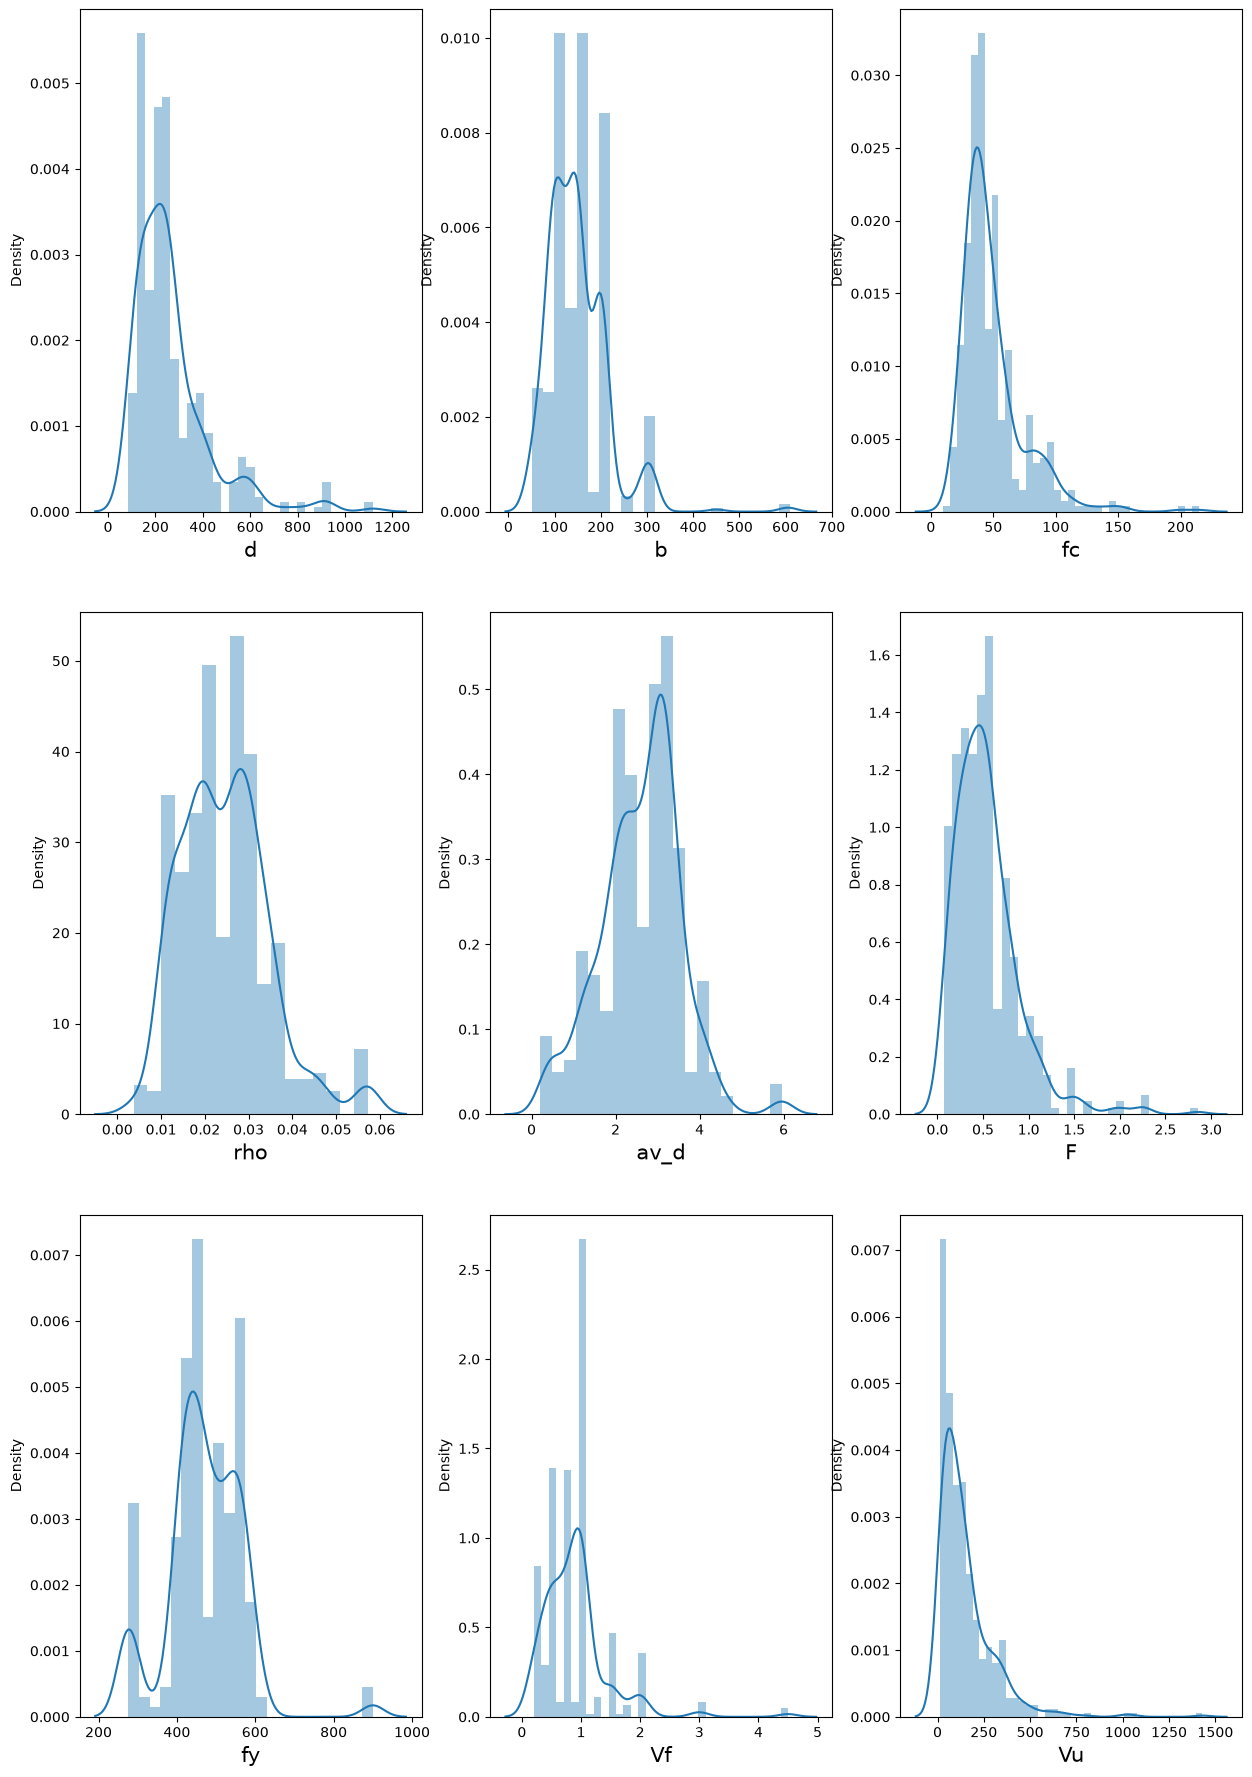

In [4]:
# Data Distribution plot
plt.figure(figsize=(15,30), facecolor = 'white')
plotnumber = 1

for column in df.columns:
    ax = plt.subplot(4,3,plotnumber)
    sns.distplot(df[column])
    plt.xlabel(column,fontsize=15)
    plotnumber+=1
plt.show()

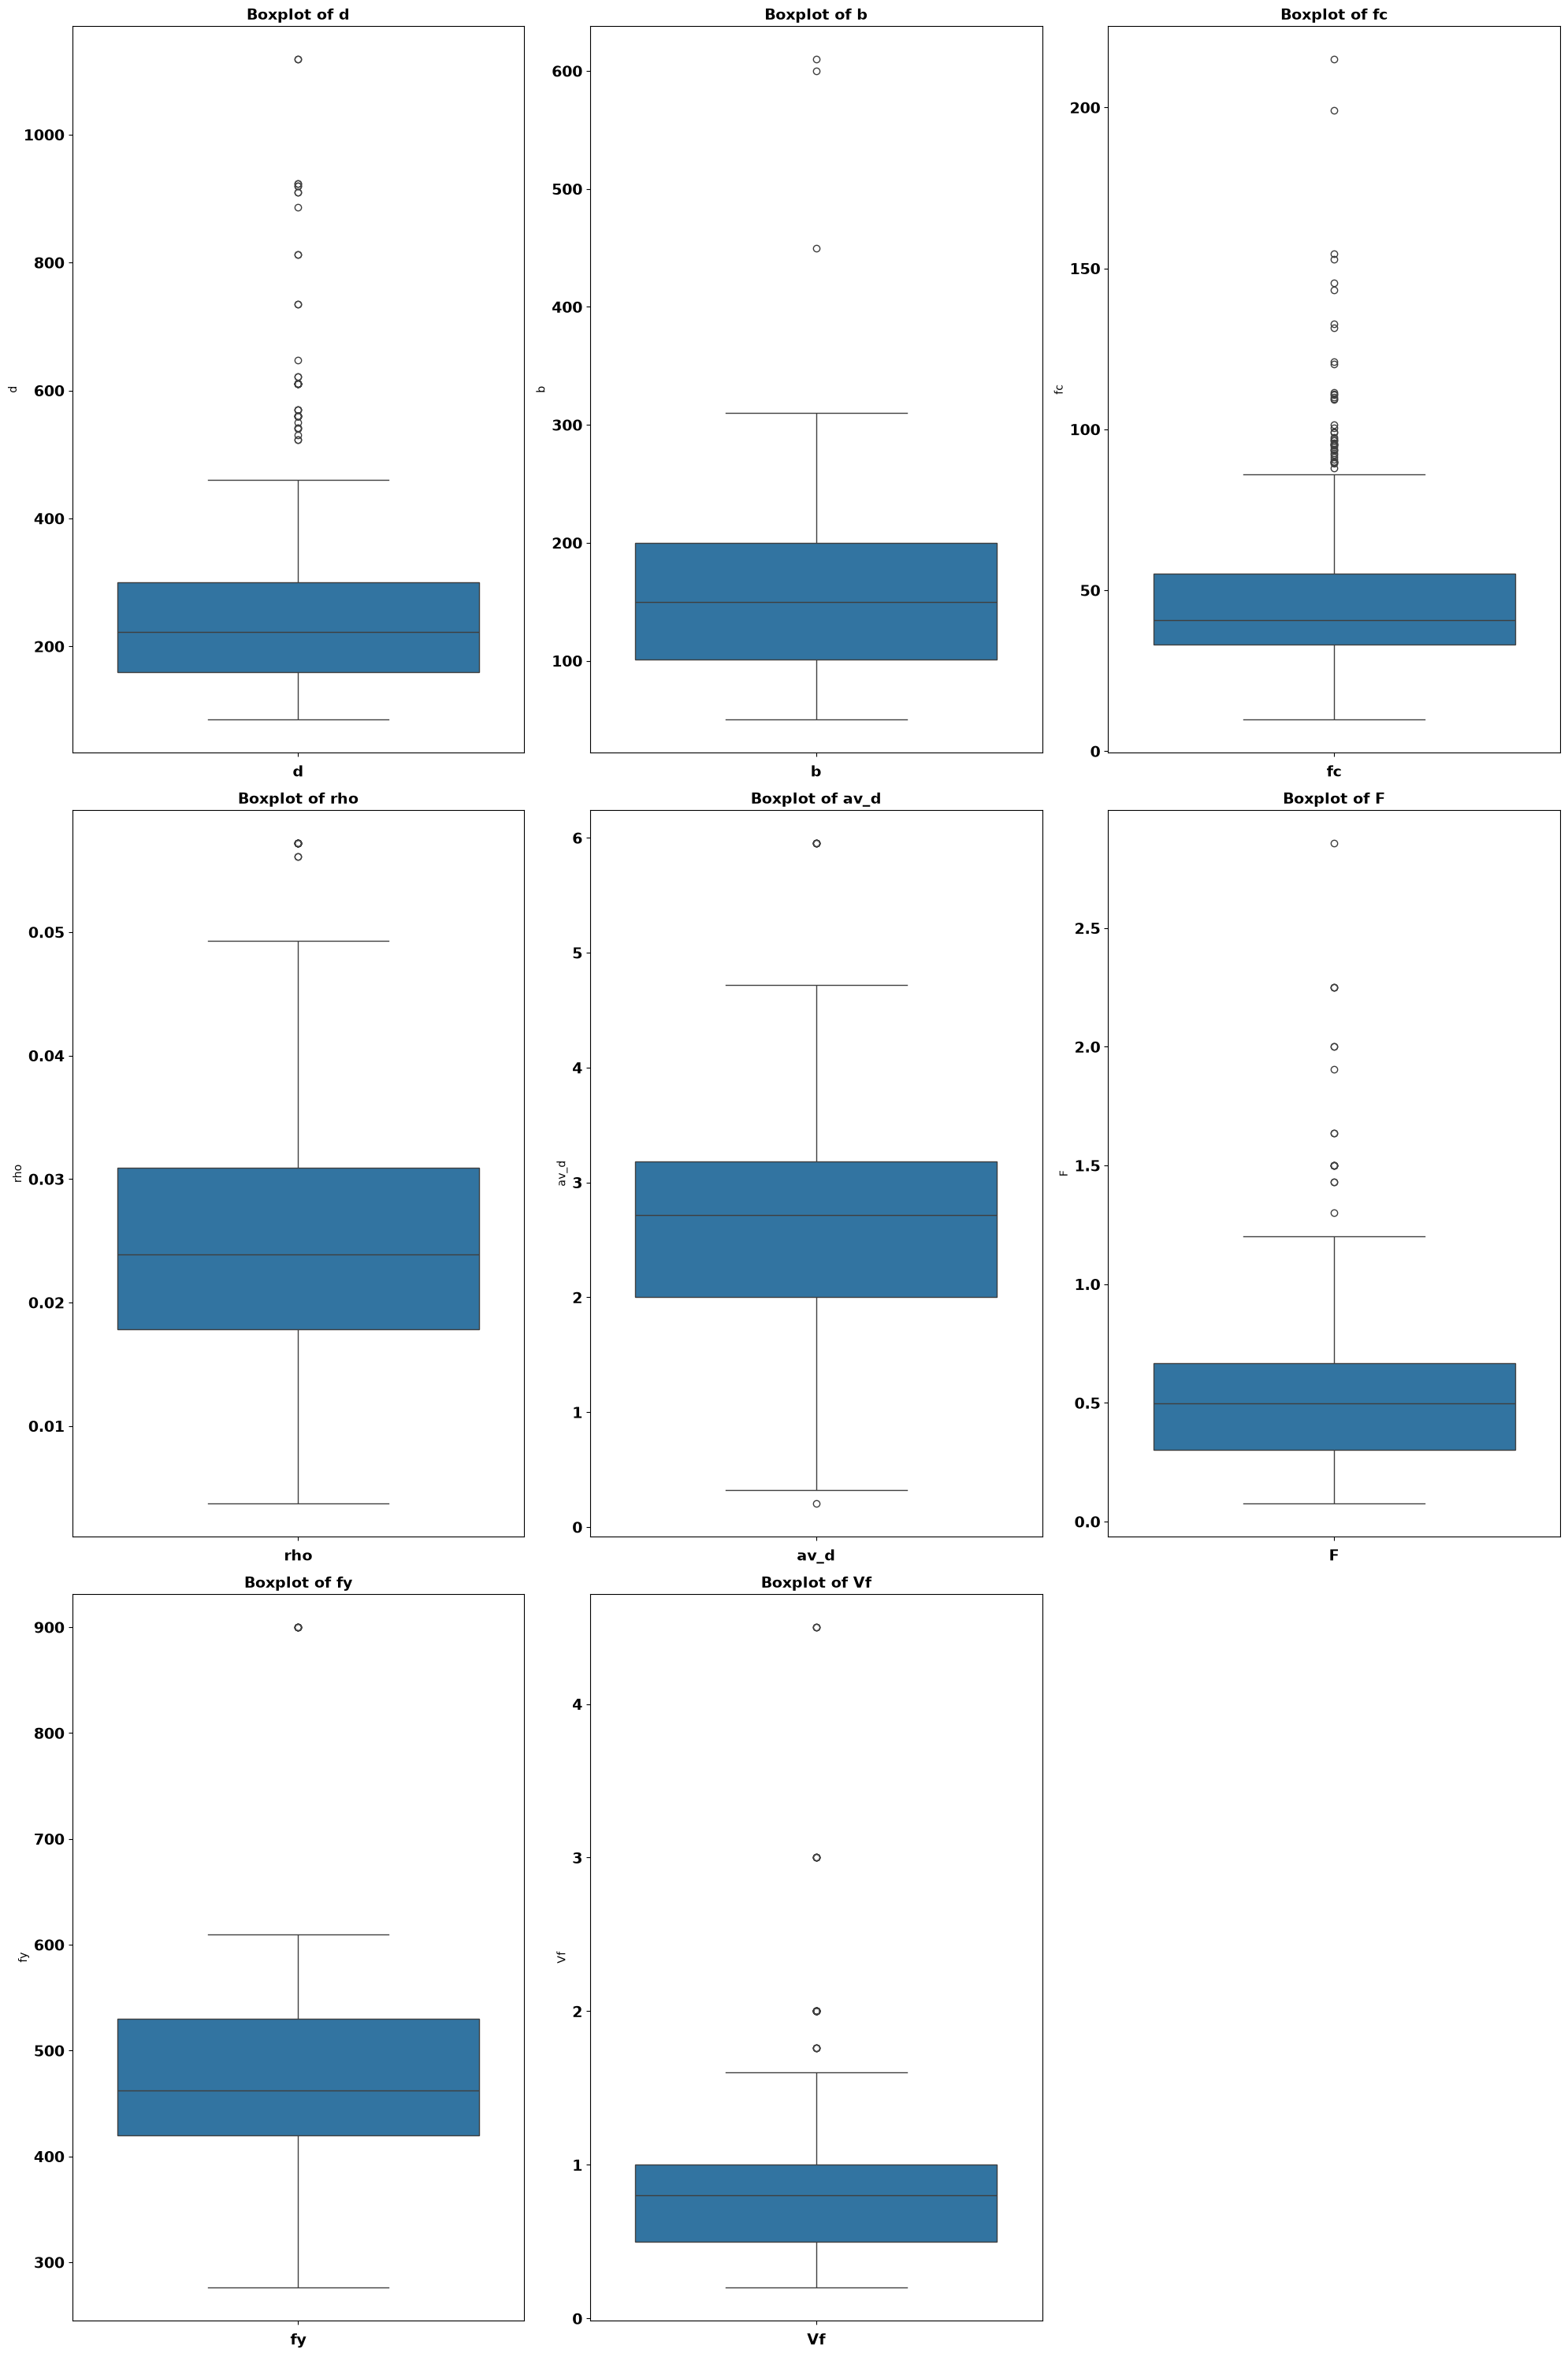

In [32]:
# check for outliers with Box plot

plt.figure(figsize=(20, 30), facecolor='white')  
plotnumber = 1

for column in X.columns:
    ax = plt.subplot((len(X.columns) // 3) + 1, 3, plotnumber)  
    sns.boxplot(y=X[column]) 
    
    # Move feature names to X-axis instead of Y-axis
    plt.xlabel(column, fontsize=14, fontweight='bold')  
    plt.title(f'Boxplot of {column}', fontsize=14, fontweight='bold')  
    
    # Ensure y-axis numbers are visible
    plt.yticks(fontsize=14, fontweight='bold')  
    
    plotnumber += 1

plt.tight_layout()  
plt.show()

## corrlation Matrix

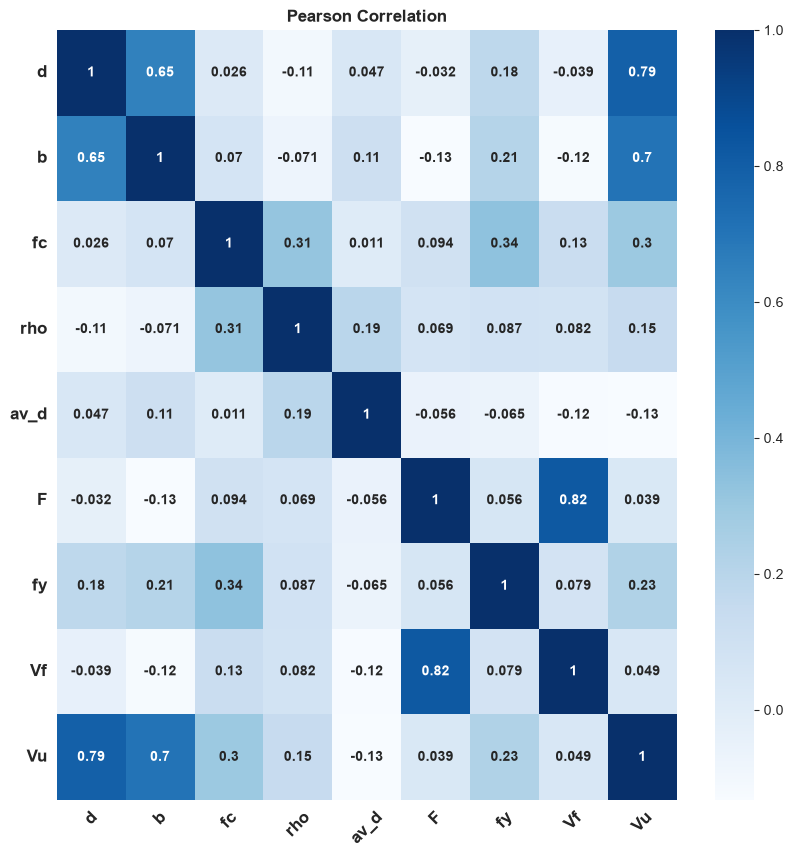

In [79]:
sns.set_style("white")
plt.figure(figsize=(10,10))
plt.title('Pearson Correlation', fontweight='bold')

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='Blues',
    annot_kws={'fontweight': 'bold'}
)

# Make axis labels (feature names) bold
plt.xticks(fontsize=12, fontweight='bold', rotation=45)
plt.yticks(fontsize=12, fontweight='bold', rotation=0)

plt.show()

## 2. Hyperparameter tuning (one tuned model, used for everything)


In [6]:
PARAM_GRID = {"max_depth": [2, 3, 4, 6, 9],
              "learning_rate": [0.01, 0.03, 0.05, 0.1],
              "n_estimators": [100, 200, 300, 500],
              "colsample_bytree": [0.3, 0.7, 1.0]}
# PARAM_GRID = {"learning_rate": [0.01, 0.05, 0.1], "n_estimators": [100, 200, 300],
#               "max_depth": [3, 6, 9, 12], "colsample_bytree": [0.3, 0.7]}
if QUICK_TEST:
    PARAM_GRID = {"max_depth": [3], "learning_rate": [0.05], "n_estimators": [100], "colsample_bytree": [0.7]}

grid = GridSearchCV(xgb.XGBRegressor(random_state=SEED_MODEL), PARAM_GRID, cv=5,
                    scoring="neg_mean_squared_error", n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

best_params = grid.best_params_
best_xgb = grid.best_estimator_          
print("Best parameters:", best_params)
print("Best CV MSE: %.2f" % -grid.best_score_)

Fitting 5 folds for each of 240 candidates, totalling 1200 fits
Best parameters: {'colsample_bytree': 0.7, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 500}
Best CV MSE: 3462.99


## 3. Table 3: 80/20, 75/25 and 70/30 splits (same tuned hyperparameters)

In [7]:
rows = []
for test_size in (0.20, 0.25, 0.30):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=test_size, random_state=SEED_SPLIT)
    m = xgb.XGBRegressor(random_state=SEED_MODEL, **best_params).fit(Xtr, ytr)
    label = f"{round((1 - test_size) * 100)}/{round(test_size * 100)}"
    for setname, (a, b) in {"Training": (ytr, m.predict(Xtr)), "Testing": (yte, m.predict(Xte))}.items():
        rows.append({"Set": setname, "Split": label, **metrics(a, b)})

table3 = (pd.DataFrame(rows).set_index(["Set", "Split"])[["MSE", "RMSE", "MAE", "R2"]].T).round(3)
table3.to_csv("results/table3_splits.csv")
table3

Set,Training,Testing,Training,Testing,Training,Testing
Split,80/20,80/20,75/25,75/25,70/30,70/30
MSE,156.621,569.442,147.286,530.447,151.451,642.773
RMSE,12.515,23.863,12.136,23.031,12.307,25.353
MAE,8.806,15.968,8.423,15.776,8.701,17.611
R2,0.993,0.977,0.993,0.976,0.994,0.967


## 4. Cross-validation



In [8]:
final_model = xgb.XGBRegressor(random_state=SEED_MODEL, **best_params)

# (a) 5-fold CV on the training partition
cv5 = KFold(n_splits=5)   # no shuffling; X_train is already randomly ordered by train_test_split
r2_folds   = cross_val_score(final_model, X_train, y_train, cv=cv5, scoring="r2")
rmse_folds = -cross_val_score(final_model, X_train, y_train, cv=cv5, scoring="neg_root_mean_squared_error")
mae_folds  = -cross_val_score(final_model, X_train, y_train, cv=cv5, scoring="neg_mean_absolute_error")
print("Fold R2:", np.round(r2_folds, 3))
print("5-fold CV on training set:  R2 = %.3f +/- %.3f (range %.3f to %.3f)"
      % (r2_folds.mean(), r2_folds.std(ddof=1), r2_folds.min(), r2_folds.max()))
print("                            RMSE = %.2f +/- %.2f kN, MAE = %.2f +/- %.2f kN"
      % (rmse_folds.mean(), rmse_folds.std(ddof=1), mae_folds.mean(), mae_folds.std(ddof=1)))

# (b) repeated shuffled 5-fold CV on the full dataset (more stable)
rkf = RepeatedKFold(n_splits=5, n_repeats=2 if QUICK_TEST else 10, random_state=SEED_MODEL)
r2_rep = cross_val_score(final_model, X, y, cv=rkf, scoring="r2")
print("Repeated 5x%d CV on all data: R2 = %.3f +/- %.3f (5th to 95th percentile %.3f to %.3f)"
      % (rkf.n_repeats, r2_rep.mean(), r2_rep.std(ddof=1), *np.percentile(r2_rep, [5, 95])))

# where does the single hold-out result sit in that distribution?
print("Hold-out test R2 (80/20): %.3f" % r2_score(y_test, best_xgb.predict(X_test)))
pd.DataFrame({"R2": r2_folds, "RMSE": rmse_folds, "MAE": mae_folds},
             index=[f"fold {i+1}" for i in range(5)]).round(3).to_csv("results/cv5_folds.csv")

Fold R2: [0.923 0.919 0.74  0.96  0.908]
5-fold CV on training set:  R2 = 0.890 +/- 0.086 (range 0.740 to 0.960)
                            RMSE = 48.23 +/- 37.70 kN, MAE = 25.36 +/- 10.69 kN
Repeated 5x10 CV on all data: R2 = 0.920 +/- 0.047 (5th to 95th percentile 0.830 to 0.967)
Hold-out test R2 (80/20): 0.977


## 5. Other models: Random Forest and SVR (tuned the same way, SVR scaled inside a pipeline)

In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rf_grid  = {"n_estimators": [200, 500], "max_depth": [None, 10, 20],
            "min_samples_leaf": [1, 2, 4], "max_features": [0.5, 1.0]}
svr_grid = {"svr__C": [1, 10, 100, 1000, 10000], "svr__gamma": ["scale", 0.01, 0.1],
            "svr__epsilon": [0.1, 1, 10]}
if QUICK_TEST:
    rf_grid  = {"n_estimators": [50], "max_depth": [10]}
    svr_grid = {"svr__C": [100], "svr__gamma": ["scale"]}

fitted_models = {"XGBoost": best_xgb}
for name, est, g in [("Random Forest", RandomForestRegressor(random_state=SEED_MODEL, n_jobs=-1), rf_grid),
                     ("SVR", make_pipeline(StandardScaler(), SVR()), svr_grid)]:
    s = GridSearchCV(est, g, cv=5, scoring="neg_mean_squared_error", n_jobs=-1).fit(X_train, y_train)
    fitted_models[name] = s.best_estimator_
    print(name, "best params:", s.best_params_)

ml_rows = []
for name, m in fitted_models.items():
    cv_r2 = cross_val_score(m, X_train, y_train, cv=5, scoring="r2")
    ml_rows.append({"Model": name, "CV R2 mean": cv_r2.mean(), "CV R2 sd": cv_r2.std(ddof=1),
                    **{f"Test {k}": v for k, v in metrics(y_test, m.predict(X_test)).items()}})
table_ml = pd.DataFrame(ml_rows).set_index("Model").round(3)
table_ml.to_csv("results/ml_model_comparison.csv")
table_ml

Random Forest best params: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 200}
SVR best params: {'svr__C': 10000, 'svr__epsilon': 10, 'svr__gamma': 0.01}


,CV R2 mean,CV R2 sd,Test R2,Test MSE,Test RMSE,Test MAE
Model,,,,,,
XGBoost,0.890,0.086,0.977,569.442,23.863,15.968
Random Forest,0.852,0.100,0.952,1184.580,34.418,21.348
SVR,0.905,0.021,0.941,1449.478,38.072,24.858


In [5]:
PARAM_GRID = {"max_depth": [2, 3, 4, 6, 9],
              "learning_rate": [0.01, 0.03, 0.05, 0.1],
              "n_estimators": [100, 200, 300, 500],
              "colsample_bytree": [0.3, 0.7, 1.0]}
if QUICK_TEST:
    PARAM_GRID = {"max_depth": [3], "learning_rate": [0.05],
                  "n_estimators": [100], "colsample_bytree": [0.7]}

grid = GridSearchCV(xgb.XGBRegressor(random_state=SEED_MODEL), PARAM_GRID,
                    cv=GroupKFold(5), scoring="neg_mean_squared_error",
                    n_jobs=-1, verbose=1)
grid.fit(X_train, y_train, groups=g_train)

best_params = grid.best_params_
best_xgb = grid.best_estimator_
print("Best parameters:", best_params)
print("Best CV MSE: %.2f" % -grid.best_score_)

Fitting 5 folds for each of 240 candidates, totalling 1200 fits
Best parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 500}
Best CV MSE: 2882.45


In [6]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold

# real study ID if you have one; otherwise the proxy used in section 12
groups = (df["source"].factorize()[0] if "source" in df.columns
          else df.groupby(["d", "b", "rho", "fy"]).ngroup().values)

tr, te = next(GroupShuffleSplit(1, test_size=0.2, random_state=SEED_SPLIT).split(X, y, groups))
X_train, X_test = X.iloc[tr], X.iloc[te]
y_train, y_test = y.iloc[tr], y.iloc[te]
g_train = groups[tr]

grid = GridSearchCV(xgb.XGBRegressor(random_state=SEED_MODEL), PARAM_GRID,
                    cv=GroupKFold(5), scoring="neg_mean_squared_error", n_jobs=-1)
grid.fit(X_train, y_train, groups=g_train)          # note groups=

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.3, 0.7, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [2, 3, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",GroupKFold(n_...shuffle=False)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... vers

## 6. Linear baseline (Table 6): OLS with p-values, VIF and ridge



In [9]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import Ridge

Xc = sm.add_constant(X)
ols_full = sm.OLS(y, Xc).fit()
vif = pd.Series({c: variance_inflation_factor(Xc.values, i) for i, c in enumerate(Xc.columns) if c != "const"})
ridge = Ridge(alpha=1.0).fit(X, y)
ridge_coef = pd.concat([pd.Series({"const": ridge.intercept_}), pd.Series(ridge.coef_, index=FEATURES)])

table6 = pd.DataFrame({"Coefficient": ols_full.params, "Std. Error": ols_full.bse,
                       "t-statistic": ols_full.tvalues, "p-value": ols_full.pvalues,
                       "VIF": vif, "Ridge (alpha=1)": ridge_coef}).reindex(["const"] + FEATURES)
table6.to_csv("results/table6_ols.csv")
print("OLS on all data: R2 = %.3f, adj. R2 = %.3f, n = %d" % (ols_full.rsquared, ols_full.rsquared_adj, len(y)))

p = ols_full.params
print("V_baseline = %.3f " % p["const"] + " ".join("%+.4f*%s" % (p[f], f) for f in FEATURES))
table6.round(4)

OLS on all data: R2 = 0.841, adj. R2 = 0.838, n = 488
V_baseline = -128.505 +0.5508*d +0.8593*b +1.2200*fc +3314.8633*rho -39.3635*av_d +31.2738*F -0.1007*fy -4.5702*Vf


,Coefficient,Std. Error,t-statistic,p-value,VIF,Ridge (alpha=1)
const,-128.5048,17.2758,-7.4384,0.0000,NaN,-85.2233
d,0.5508,0.0226,24.4001,0.0000,1.7575,0.5334
b,0.8593,0.0569,15.0986,0.0000,1.8246,0.8303
fc,1.2200,0.1217,10.0229,0.0000,1.2571,1.6066
rho,3314.8633,295.1724,11.2303,0.0000,1.1842,132.7989
av_d,-39.3635,3.0188,-13.0393,0.0000,1.0946,-32.1956
F,31.2738,13.4198,2.3304,0.0202,3.1173,28.2773
fy,-0.1007,0.0307,-3.2765,0.0011,1.1928,-0.0934
Vf,-4.5702,8.8596,-0.5158,0.6062,3.1746,0.3255


In [10]:
# Fair comparison: baseline fitted on the training set only, evaluated on the same test set as XGBoost
ols_train = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print("OLS (train fit) test metrics:", {k: round(v, 3) for k, v in
      metrics(y_test, ols_train.predict(sm.add_constant(X_test, has_constant="add"))).items()})

OLS (train fit) test metrics: {'R2': 0.851, 'MSE': 3646.505, 'RMSE': np.float64(60.386), 'MAE': 39.112}


## 7. Empirical formulas, Tables 7 and 8, Figures 5 and 11


In [11]:
def aci318_19(D):          
    lam_s = np.minimum(1.0, np.sqrt(2.0 / (1.0 + 0.004 * D["d"])))
    return 0.66 * lam_s * np.cbrt(D["rho"]) * np.sqrt(D["fc"]) * D["b"] * D["d"] / 1000.0

def eurocode2(D):          
    k = np.minimum(2.0, 1.0 + np.sqrt(200.0 / D["d"]))
    rho_l = np.minimum(D["rho"], 0.02)
    return 0.12 * k * np.cbrt(100.0 * rho_l * D["fc"]) * D["b"] * D["d"] / 1000.0

def sharma_1986(D):        # v = (2/3)(0.8 sqrt(fc))(d/a)^0.25
    return (2.0 / 3.0) * 0.8 * np.sqrt(D["fc"]) * (1.0 / D["av_d"]) ** 0.25 * D["b"] * D["d"] / 1000.0

ASHOUR_RHO_SCALE = 1.0     
def ashour_1992(D):        # v = (0.7 sqrt(fc) + 7F)(d/a) + 17.2 rho (d/a)
    d_a = 1.0 / D["av_d"]
    v = (0.7 * np.sqrt(D["fc"]) + 7.0 * D["F"]) * d_a + 17.2 * ASHOUR_RHO_SCALE * D["rho"] * d_a
    return v * D["b"] * D["d"] / 1000.0

EMPIRICAL = {"ACI 318-19": aci318_19, "Eurocode 2": eurocode2,
             "Sharma (1986)": sharma_1986, "Ashour (1992)": ashour_1992}


In [12]:
preds = {name: m.predict(X_test) for name, m in fitted_models.items()}
preds["OLS baseline"] = np.asarray(ols_train.predict(sm.add_constant(X_test, has_constant="add")))
for name, f in EMPIRICAL.items():
    preds[name] = np.asarray(f(X_test))

# Table 8 computed on the FULL test set (not 10 hand-picked beams)
table8 = pd.DataFrame({name: metrics(y_test, p) for name, p in preds.items()}).T[["R2", "MSE", "RMSE", "MAE"]].round(3)
table8 = table8.sort_values("R2", ascending=False)
table8.to_csv("results/table8_model_comparison.csv")
print("Test set size:", len(y_test))
table8

Test set size: 98


,R2,MSE,RMSE,MAE
XGBoost,0.977,569.442,23.863,15.968
Random Forest,0.952,1184.580,34.418,21.348
SVR,0.941,1449.478,38.072,24.858
OLS baseline,0.851,3646.505,60.386,39.112
Sharma (1986),0.769,5677.474,75.349,43.864
ACI 318-19,0.060,23061.149,151.859,98.154
Eurocode 2,-0.068,26223.789,161.938,108.024
Ashour (1992),-0.120,27478.691,165.767,62.796


In [13]:
n_show = 98
table7 = pd.DataFrame({"V_exp": y_test.values[:n_show], **{k: v[:n_show] for k, v in preds.items()}},
                      index=[f"B{i+1}" for i in range(n_show)]).round(2)
table7.to_csv("results/table7_first98_test_beams.csv")
table7

,V_exp,XGBoost,Random Forest,SVR,OLS baseline,ACI 318-19,Eurocode 2,Sharma (1986),Ashour (1992)
B1,342.00,340.920013,345.03,338.10,254.71,46.32,32.82,144.22,663.25
B2,33.70,26.719999,30.83,28.55,21.65,16.85,13.29,31.92,24.06
B3,351.52,342.010010,346.52,346.20,280.56,70.20,69.01,261.82,292.54
B4,1008.00,1042.689941,865.85,862.69,708.38,283.18,270.26,950.45,906.21
B5,32.20,28.209999,35.16,20.43,30.42,15.44,11.40,28.49,31.52
...,...,...,...,...,...,...,...,...,...
B94,26.01,26.240000,24.19,33.35,-13.12,15.31,12.47,27.86,16.88
B95,24.95,31.510000,34.37,0.55,81.19,15.07,10.13,23.95,29.49
B96,119.70,94.919998,93.13,107.08,156.26,34.08,22.80,70.71,77.72
B97,32.50,40.189999,45.43,50.18,33.15,21.14,21.62,54.65,71.92


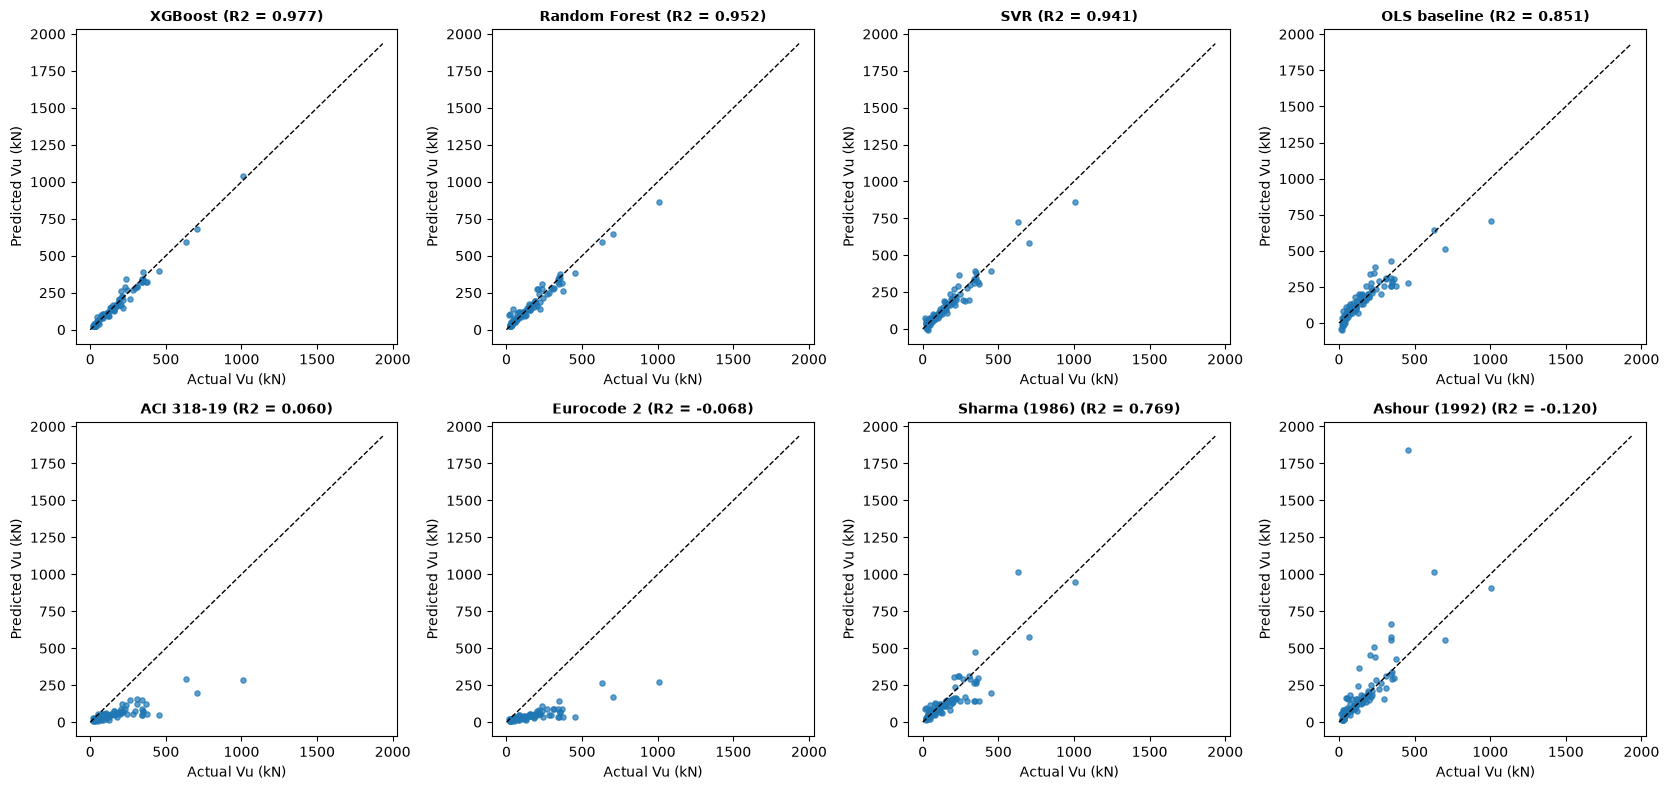

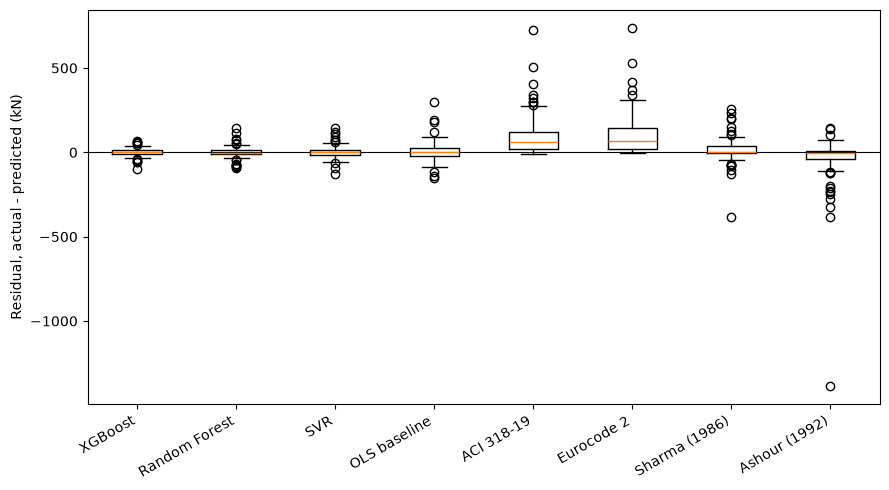

In [14]:
names = list(preds)
ncol = 4
nrow = int(np.ceil(len(names) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 4 * nrow))
lim = [0, max(y_test.max(), max(p.max() for p in preds.values())) * 1.05]
for ax, n in zip(axes.ravel(), names):
    ax.scatter(y_test, preds[n], s=14, alpha=0.7)
    ax.plot(lim, lim, "k--", lw=1)
    ax.set_title("%s (R2 = %.3f)" % (n, table8.loc[n, "R2"]), fontsize=10, fontweight="bold")
    ax.set_xlabel("Actual Vu (kN)"); ax.set_ylabel("Predicted Vu (kN)")
for ax in axes.ravel()[len(names):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig("results/fig_actual_vs_predicted.png", dpi=300); plt.show()

# Figure 12: error distribution
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot([np.asarray(y_test) - preds[n] for n in names], showfliers=True)
ax.set_xticks(range(1, len(names) + 1))
ax.set_xticklabels(names, rotation=30, ha="right")   
ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("Residual, actual - predicted (kN)")
plt.tight_layout()
plt.savefig("results/fig_error_distribution.png", dpi=300); plt.show()

## 8. XGBoost feature importance: gain, weight, cover (Fig. 8)

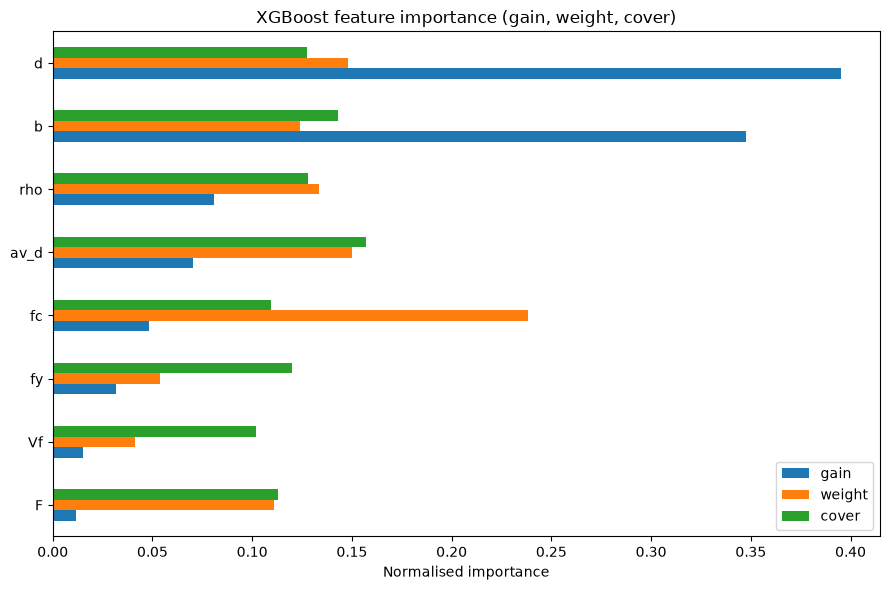

,gain,weight,cover,sklearn feature_importances_
d,0.3950,0.1479,0.1276,0.3950
b,0.3474,0.1241,0.1432,0.3474
fc,0.0481,0.2385,0.1094,0.0481
rho,0.0807,0.1335,0.1282,0.0807
av_d,0.0703,0.1499,0.1571,0.0703
F,0.0116,0.1107,0.1128,0.0116
fy,0.0317,0.0540,0.1200,0.0317
Vf,0.0152,0.0413,0.1017,0.0152


In [15]:
booster = best_xgb.get_booster()
imp = pd.DataFrame({t: pd.Series(booster.get_score(importance_type=t)) for t in ["gain", "weight", "cover"]})
imp = imp.reindex(FEATURES).fillna(0.0)
imp_norm = (imp / imp.sum()).round(4)
imp_norm["sklearn feature_importances_"] = best_xgb.feature_importances_.round(4)
imp_norm.to_csv("results/xgb_feature_importance.csv")

imp_norm.drop(columns="sklearn feature_importances_").sort_values("gain").plot.barh(figsize=(9, 6))
plt.xlabel("Normalised importance"); plt.title("XGBoost feature importance (gain, weight, cover)")
plt.tight_layout(); plt.savefig("results/fig_feature_importance.png", dpi=300); plt.show()
imp_norm

## 9. SHAP (Figs. 6 and 7), bootstrap stability, and Vf-excluded re-run

Everything is on `best_xgb` with correct labels and raw units.

In [16]:
import shap

explainer = shap.TreeExplainer(best_xgb)
sv = explainer(X_train)                       

# sanity check: base value + sum of SHAP values must reproduce the prediction
recon = sv.base_values + sv.values.sum(axis=1)
assert np.allclose(recon, best_xgb.predict(X_train), atol=1e-2), "SHAP additivity check failed"
print("Base value E[f(x)] = %.3f kN" % float(np.ravel(explainer.expected_value)[0]))

mean_abs = pd.Series(np.abs(sv.values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
mean_abs.round(2).to_csv("results/shap_mean_abs.csv")
print(mean_abs.round(2))

Base value E[f(x)] = 147.857 kN
d       52.790001
b       37.369999
av_d    22.370001
fc      18.840000
rho     16.730000
F        5.740000
Vf       4.220000
fy       3.750000
dtype: float32


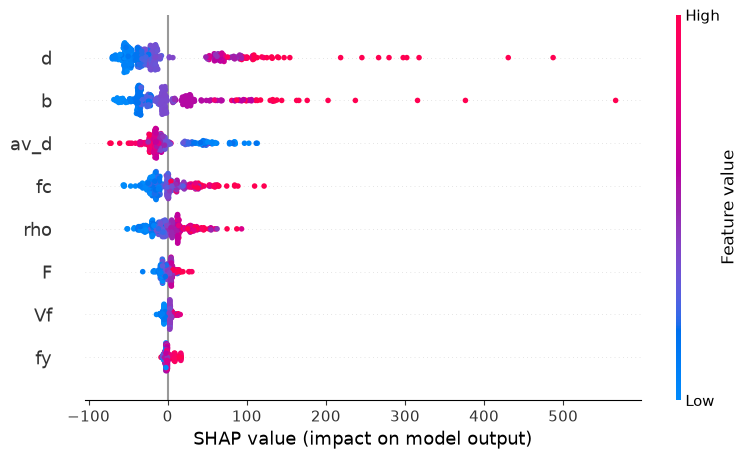

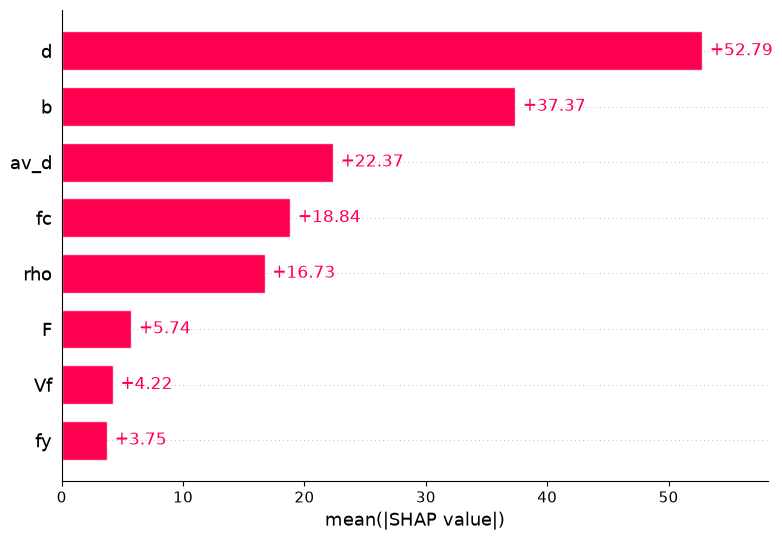

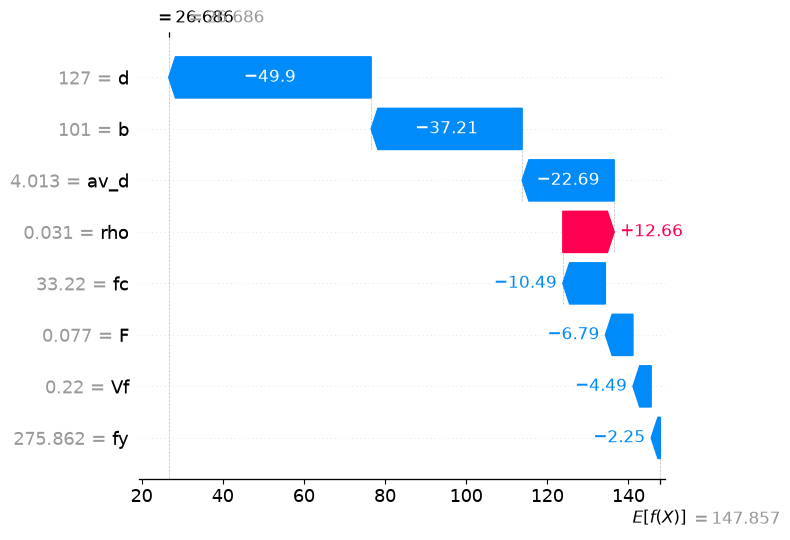

Beam 0 inputs: {'d': 127.0, 'b': 101.0, 'fc': 33.22, 'rho': 0.0309, 'av_d': 4.0126, 'F': 0.0767, 'fy': 275.8621, 'Vf': 0.22}


In [17]:
plt.figure(); shap.plots.beeswarm(sv, show=False); plt.tight_layout()
plt.savefig("results/fig_shap_beeswarm.png", dpi=300, bbox_inches="tight"); plt.show()

plt.figure(); shap.plots.bar(sv, show=False); plt.tight_layout()
plt.savefig("results/fig_shap_bar.png", dpi=300, bbox_inches="tight"); plt.show()

i = 0   # change to explain a different training beam
plt.figure(); shap.plots.waterfall(sv[i], show=False); plt.tight_layout()
plt.savefig("results/fig_shap_waterfall.png", dpi=300, bbox_inches="tight"); plt.show()
print("Beam", i, "inputs:", X_train.iloc[i].round(4).to_dict()) 

In [18]:
# Bootstrap stability of the SHAP ranking (refit on each resample, SHAP evaluated on the fixed training set)
rng = np.random.default_rng(SEED_MODEL)
boot_imp = []
for b in range(N_BOOT):
    idx = rng.integers(0, len(X_train), len(X_train))
    m = xgb.XGBRegressor(random_state=SEED_MODEL + b, **best_params).fit(X_train.iloc[idx], y_train.iloc[idx])
    boot_imp.append(np.abs(shap.TreeExplainer(m).shap_values(X_train)).mean(axis=0))
boot_imp = pd.DataFrame(boot_imp, columns=FEATURES)
ranks = boot_imp.rank(axis=1, ascending=False)

stability = pd.DataFrame({"mean |SHAP|": boot_imp.mean(), "sd": boot_imp.std(ddof=1),
                          "mean rank": ranks.mean(),
                          f"in top 4 (of {N_BOOT})": (ranks <= 4).sum()}).sort_values("mean rank").round(2)
stability.to_csv("results/shap_bootstrap_stability.csv")
stability

,mean |SHAP|,sd,mean rank,in top 4 (of 20)
d,54.869999,4.64,1.00,20
b,35.630001,4.07,2.00,20
av_d,22.129999,2.23,3.05,20
fc,18.320000,2.42,4.20,15
rho,15.160000,2.71,4.75,5
F,6.310000,1.74,6.25,0
fy,3.930000,1.06,7.30,0
Vf,3.660000,1.20,7.45,0


In [19]:
# 95% intervals and full rank-frequency table for the bootstrap SHAP ranking
stability["95% CI low"] = boot_imp.quantile(0.025).round(2)
stability["95% CI high"] = boot_imp.quantile(0.975).round(2)
rank_freq = (ranks.round().astype(int).apply(lambda c: c.value_counts())
             .reindex(range(1, len(FEATURES) + 1)).fillna(0).astype(int).T)
rank_freq.columns = [f"rank {r}" for r in rank_freq.columns]
rank_freq = rank_freq.loc[stability.index]
stability.to_csv("results/shap_bootstrap_stability.csv"); rank_freq.to_csv("results/shap_rank_frequency.csv")
print(stability); print(); print(rank_freq)

      mean |SHAP|    sd  mean rank  in top 4 (of 20)  95% CI low  95% CI high
d       54.869999  4.64       1.00                20       48.06        65.32
b       35.630001  4.07       2.00                20       27.62        41.47
av_d    22.129999  2.23       3.05                20       17.68        24.60
fc      18.320000  2.42       4.20                15       15.13        22.93
rho     15.160000  2.71       4.75                 5       10.71        20.53
F        6.310000  1.74       6.25                 0        3.79         9.55
fy       3.930000  1.06       7.30                 0        2.27         5.88
Vf       3.660000  1.20       7.45                 0        1.73         5.68

      rank 1  rank 2  rank 3  rank 4  rank 5  rank 6  rank 7  rank 8
d         20       0       0       0       0       0       0       0
b          0      20       0       0       0       0       0       0
av_d       0       0      19       1       0       0       0       0
fc         0       0 

In [85]:
# Fibre variables: F and Vf are correlated (r ~ 0.8). Check how the ranking changes without Vf,
# and report the pair as one group.
feat_noVf = [f for f in FEATURES if f != "Vf"]
m_noVf = xgb.XGBRegressor(random_state=SEED_MODEL, **best_params).fit(X_train[feat_noVf], y_train)
sv_noVf = np.abs(shap.TreeExplainer(m_noVf).shap_values(X_train[feat_noVf])).mean(axis=0)
rank_noVf = pd.Series(sv_noVf, index=feat_noVf).sort_values(ascending=False)

full_vals = pd.DataFrame(sv.values, columns=FEATURES)
group = np.abs(full_vals["F"] + full_vals["Vf"]).mean()
print("Test R2 without Vf: %.3f (with Vf: %.3f)" % (r2_score(y_test, m_noVf.predict(X_test[feat_noVf])),
                                                  r2_score(y_test, best_xgb.predict(X_test))))
print("\nRanking WITHOUT Vf:\n", rank_noVf.round(2))
print("\nFull model: mean|SHAP| F = %.2f, Vf = %.2f, grouped |SHAP_F + SHAP_Vf| = %.2f"
      % (mean_abs["F"], mean_abs["Vf"], group))
print("Reduced model: mean|SHAP| F = %.2f" % rank_noVf["F"])

Test R2 without Vf: 0.977 (with Vf: 0.977)

Ranking WITHOUT Vf:
 d       52.450001
b       36.860001
av_d    22.639999
fc      18.879999
rho     18.030001
F        7.890000
fy       3.310000
dtype: float32

Full model: mean|SHAP| F = 5.74, Vf = 4.22, grouped |SHAP_F + SHAP_Vf| = 8.81
Reduced model: mean|SHAP| F = 7.89


## 10. PDP (Fig. 9) and LIME (Fig. 10), both on the same tuned model in raw units

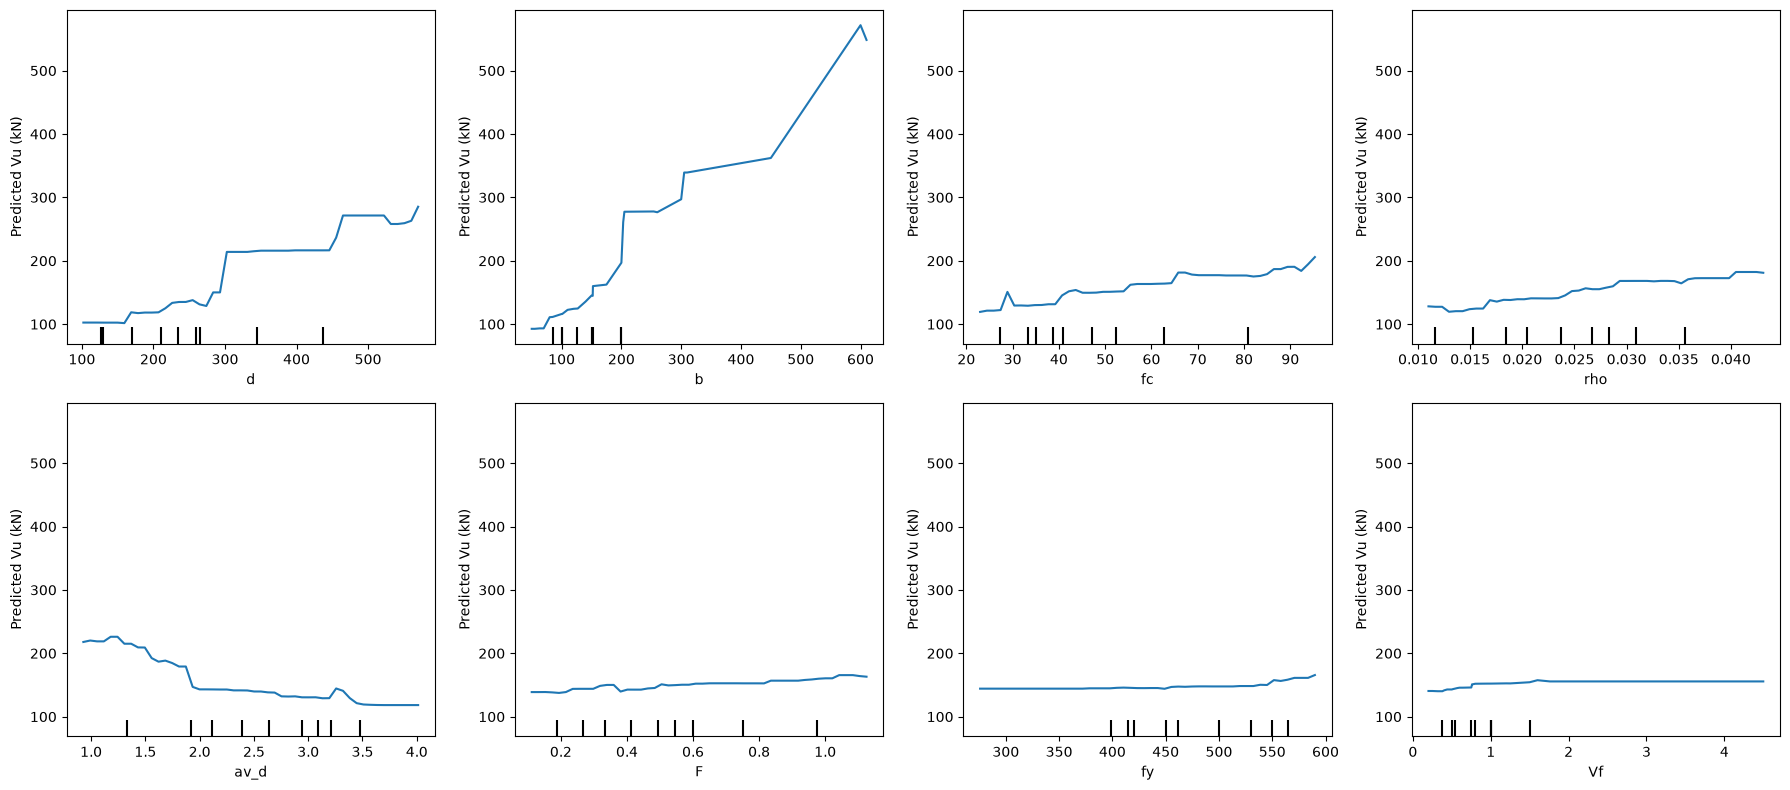

In [20]:
from sklearn.inspection import PartialDependenceDisplay

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
PartialDependenceDisplay.from_estimator(best_xgb, X_train, FEATURES, ax=axes.ravel(), grid_resolution=50)
for ax in axes.ravel():
    ax.set_ylabel("Predicted Vu (kN)")
plt.tight_layout(); plt.savefig("results/fig_pdp.png", dpi=300); plt.show()

Test beam 0 inputs: {'d': 345.0, 'b': 100.0, 'fc': 45.59, 'rho': 0.0355, 'av_d': 0.5507, 'F': 0.75, 'fy': 550.0, 'Vf': 1.0}
Model prediction: 340.92 kN   actual: 342.00 kN
LIME local weights (raw units, so thresholds are readable):
  d > 300.00                           +166.23
  av_d <= 1.99                          +72.52
  b <= 100.00                           -55.74
  rho > 0.03                            +38.08
  F > 0.65                              +15.31
  fy > 530.00                            +6.37
  40.92 < fc <= 55.70                    +5.83
  0.80 < Vf <= 1.00                      +4.32


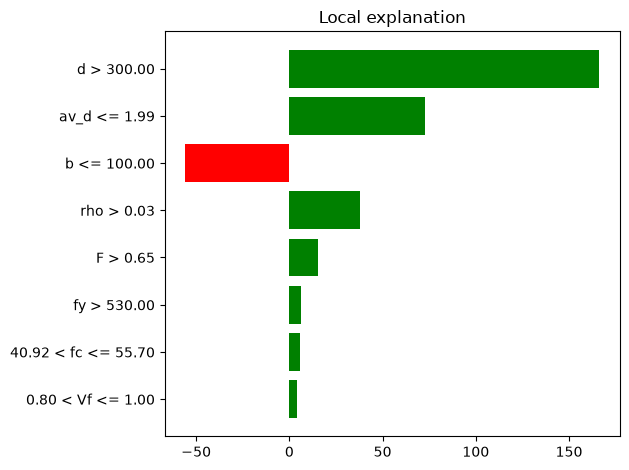

In [21]:
import lime.lime_tabular

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values, feature_names=FEATURES, mode="regression", random_state=42)

predict_fn = lambda a: best_xgb.predict(pd.DataFrame(a, columns=FEATURES))
sample = X_test.iloc[0]
exp = lime_explainer.explain_instance(sample.values, predict_fn, num_features=len(FEATURES))

print("Test beam 0 inputs:", sample.round(4).to_dict())
print("Model prediction: %.2f kN   actual: %.2f kN" % (predict_fn(sample.values.reshape(1, -1))[0], y_test.iloc[0]))
print("LIME local weights (raw units, so thresholds are readable):")
for rule, w in exp.as_list():
    print("  %-35s %+8.2f" % (rule, w))

fig = exp.as_pyplot_figure(); plt.tight_layout()
fig.savefig("results/fig_lime.png", dpi=300, bbox_inches="tight"); plt.show()

## 11. Save the deployable model and a short run summary

In [22]:
best_xgb.save_model("results/xgb_best.json")             
with open("results/xgb_best.pkl", "wb") as f:             
    pickle.dump(best_xgb, f)

# Reload test: no scaler is needed because the model was trained on raw inputs.
loaded = xgb.XGBRegressor(); loaded.load_model("results/xgb_best.json")
assert np.allclose(loaded.predict(X_test), best_xgb.predict(X_test))

example = pd.DataFrame([[221, 152, 34, 0.012, 2.45, 0.3, 448, 0.5]], columns=FEATURES)   
print("Example prediction: %.2f kN" % loaded.predict(example)[0])

summary = {"n_records": len(df), "n_train": len(X_train), "n_test": len(X_test), "best_params": best_params,
           "test_R2": r2_score(y_test, best_xgb.predict(X_test)),
           "cv5_R2_mean": r2_folds.mean(), "cv5_R2_sd": r2_folds.std(ddof=1),
           "repeated_cv_R2_mean": r2_rep.mean(), "ols_full_R2": ols_full.rsquared}
pd.Series(summary).to_csv("results/run_summary.csv")
pd.Series(summary)

Example prediction: 66.39 kN


n_records                                                            488
n_train                                                              390
n_test                                                                98
best_params            {'colsample_bytree': 0.7, 'learning_rate': 0.0...
test_R2                                                           0.9768
cv5_R2_mean                                                     0.890024
cv5_R2_sd                                                       0.085932
repeated_cv_R2_mean                                             0.920496
ols_full_R2                                                     0.840793
dtype: object

## 12. Robustness checks requested by reviewer


In [20]:
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.linear_model import LinearRegression

groups = df.groupby(["d", "b", "rho", "fy"]).ngroup().values     
gsize = pd.Series(groups).value_counts()
print("proxy series:", gsize.size, "| largest:", gsize.max(), "beams | singletons:", int((gsize == 1).sum()))
train_groups = set(groups[X_train.index])
share = np.mean([g in train_groups for g in groups[X_test.index]])
print("Test beams whose series also appears in the training set: %.0f%%" % (100 * share))

proxy series: 123 | largest: 43 beams | singletons: 30
Test beams whose series also appears in the training set: 90%


In [21]:
def make():
    return xgb.XGBRegressor(random_state=SEED_MODEL, **best_params)

# (a) repeated 5-fold CV: random vs grouped, XGBoost vs the OLS baseline
N_REP = 2 if QUICK_TEST else 5
rows = []
for rep in range(N_REP):
    perm = np.random.default_rng(rep).permutation(groups.max() + 1)[groups]
    schemes = {"random": KFold(5, shuffle=True, random_state=rep).split(X),
               "grouped": GroupKFold(5).split(X, y, perm)}
    for scheme, splits in schemes.items():
        for tr, te in splits:
            for name, mdl in (("XGBoost", make()), ("OLS baseline", LinearRegression())):
                pr = mdl.fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te])
                rows.append({"scheme": scheme, "model": name, **metrics(y.iloc[te], pr)})
cv_compare = pd.DataFrame(rows).groupby(["scheme", "model"])[["R2", "RMSE"]].agg(["mean", "std"]).round(3)
cv_compare.to_csv("results/cv_random_vs_grouped.csv")
cv_compare

R2           RMSE        
                       mean    std    mean     std
scheme  model                                     
grouped OLS baseline  0.781  0.079  65.304  12.413
        XGBoost       0.832  0.057  58.471  16.948
random  OLS baseline  0.827  0.023  61.493  10.683
        XGBoost       0.921  0.054  40.892  18.737

In [22]:
# (b) repeated 80/20 hold-out: how typical is the single split used in the paper (random_state = 64)?
N_HO = 5 if QUICK_TEST else 20
ho = []
for s_ in range(N_HO):
    tr, te = train_test_split(np.arange(len(X)), test_size=0.2, random_state=s_)
    m_ = make().fit(X.iloc[tr], y.iloc[tr]); ho.append(("random",) + tuple(metrics(y.iloc[te], m_.predict(X.iloc[te])).values()))
    tr, te = next(GroupShuffleSplit(1, test_size=0.2, random_state=s_).split(X, y, groups))
    m_ = make().fit(X.iloc[tr], y.iloc[tr]); ho.append(("grouped",) + tuple(metrics(y.iloc[te], m_.predict(X.iloc[te])).values()))
ho = pd.DataFrame(ho, columns=["split", "R2", "MSE", "RMSE", "MAE"])
summ = ho.groupby("split").agg(R2_mean=("R2", "mean"), R2_p5=("R2", lambda v: v.quantile(.05)),
                               R2_p95=("R2", lambda v: v.quantile(.95)), RMSE_mean=("RMSE", "mean")).round(3)
summ.to_csv("results/holdout_random_vs_grouped.csv")
print("Paper's single split (seed 64): R2 = %.3f" % r2_score(y_test, best_xgb.predict(X_test)))
summ

Paper's single split (seed 64): R2 = 0.977


,R2_mean,R2_p5,R2_p95,RMSE_mean
split,,,,
grouped,0.841,0.794,0.899,54.432
random,0.923,0.841,0.969,40.791


### 12.1 Confidence intervals on the test-set metrics (paired bootstrap over the 80/20 test beams)

In [23]:
B = 300 if QUICK_TEST else 2000
rng = np.random.default_rng(0)
yt = y_test.values
ii = rng.integers(0, len(yt), (B, len(yt)))
boot = {n: np.array([[r2_score(yt[i], p[i]), np.sqrt(np.mean((yt[i] - p[i]) ** 2))] for i in ii]) for n, p in preds.items()}
ci_tab = pd.DataFrame({n: {"R2": r2_score(yt, preds[n]), "R2 2.5%": np.percentile(b[:, 0], 2.5), "R2 97.5%": np.percentile(b[:, 0], 97.5),
                           "RMSE": np.sqrt(np.mean((yt - preds[n]) ** 2)), "RMSE 2.5%": np.percentile(b[:, 1], 2.5),
                           "RMSE 97.5%": np.percentile(b[:, 1], 97.5),
                           "P(XGBoost RMSE < this model)": np.mean(boot["XGBoost"][:, 1] < b[:, 1]) if n != "XGBoost" else np.nan}
                       for n, b in boot.items()}).T.round(3)
ci_tab.to_csv("results/test_metric_confidence_intervals.csv")
ci_tab

,R2,R2 2.5%,R2 97.5%,RMSE,RMSE 2.5%,RMSE 97.5%,P(XGBoost RMSE < this model)
XGBoost,0.977,0.947,0.989,23.863,18.200,29.233,NaN
Random Forest,0.952,0.911,0.969,34.418,25.726,42.746,0.998
SVR,0.941,0.896,0.958,38.072,29.035,46.854,1.000
OLS baseline,0.851,0.776,0.891,60.386,43.539,77.451,1.000
ACI 318-19,0.060,-0.271,0.211,151.859,112.516,192.598,1.000
Eurocode 2,-0.068,-0.477,0.112,161.938,123.201,202.571,1.000
Sharma (1986),0.769,0.543,0.899,75.349,51.925,97.475,1.000
Ashour (1992),-0.120,-2.609,0.813,165.767,70.030,263.029,1.000


### 12.2 Residual and learning-curve diagnostics (overfitting check)

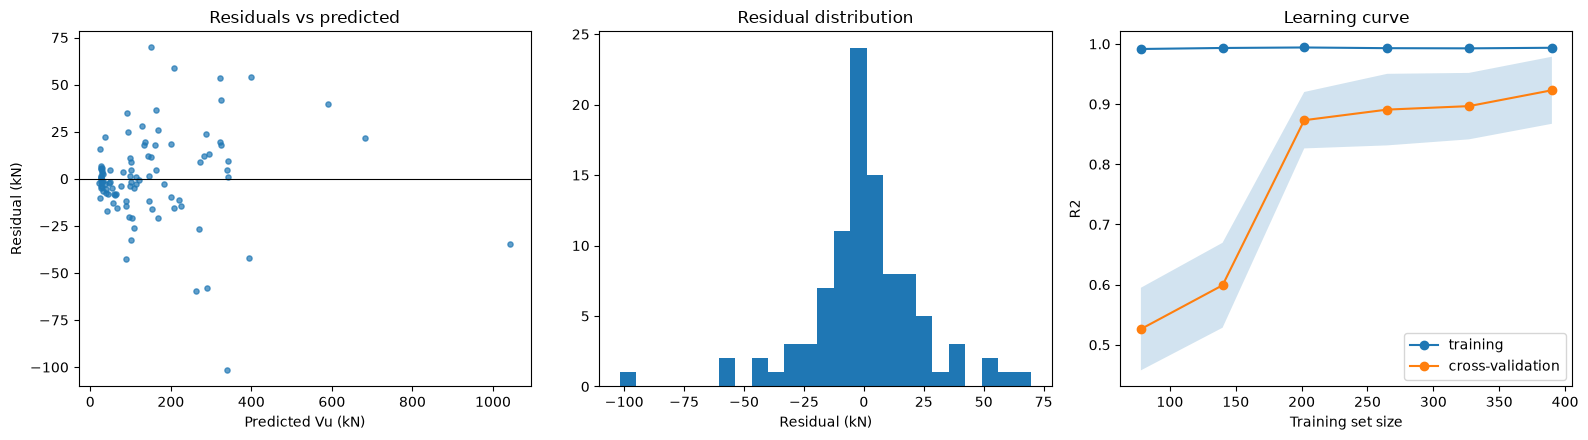

Median |error|/Vu = 10.0%; 90th percentile = 29.5%


In [24]:
from sklearn.model_selection import learning_curve
res_ = yt - preds["XGBoost"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(preds["XGBoost"], res_, s=14, alpha=.7); ax[0].axhline(0, color="k", lw=.8)
ax[0].set_xlabel("Predicted Vu (kN)"); ax[0].set_ylabel("Residual (kN)"); ax[0].set_title("Residuals vs predicted")
ax[1].hist(res_, bins=25); ax[1].set_xlabel("Residual (kN)"); ax[1].set_title("Residual distribution")
sizes, tr_sc, va_sc = learning_curve(make(), X, y, train_sizes=np.linspace(0.2, 1.0, 6),
                                     cv=KFold(5, shuffle=True, random_state=0), scoring="r2")
ax[2].plot(sizes, tr_sc.mean(1), "o-", label="training"); ax[2].plot(sizes, va_sc.mean(1), "o-", label="cross-validation")
ax[2].fill_between(sizes, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), alpha=.2)
ax[2].set_xlabel("Training set size"); ax[2].set_ylabel("R2"); ax[2].set_title("Learning curve"); ax[2].legend()
plt.tight_layout(); plt.savefig("results/fig_diagnostics.png", dpi=300); plt.show()
rel = np.abs(res_) / np.maximum(yt, 1e-9)
print("Median |error|/Vu = %.1f%%; 90th percentile = %.1f%%" % (100 * np.median(rel), 100 * np.percentile(rel, 90)))

### 12.3 Correlated features: SHAP dependence and ALE next to the PDP

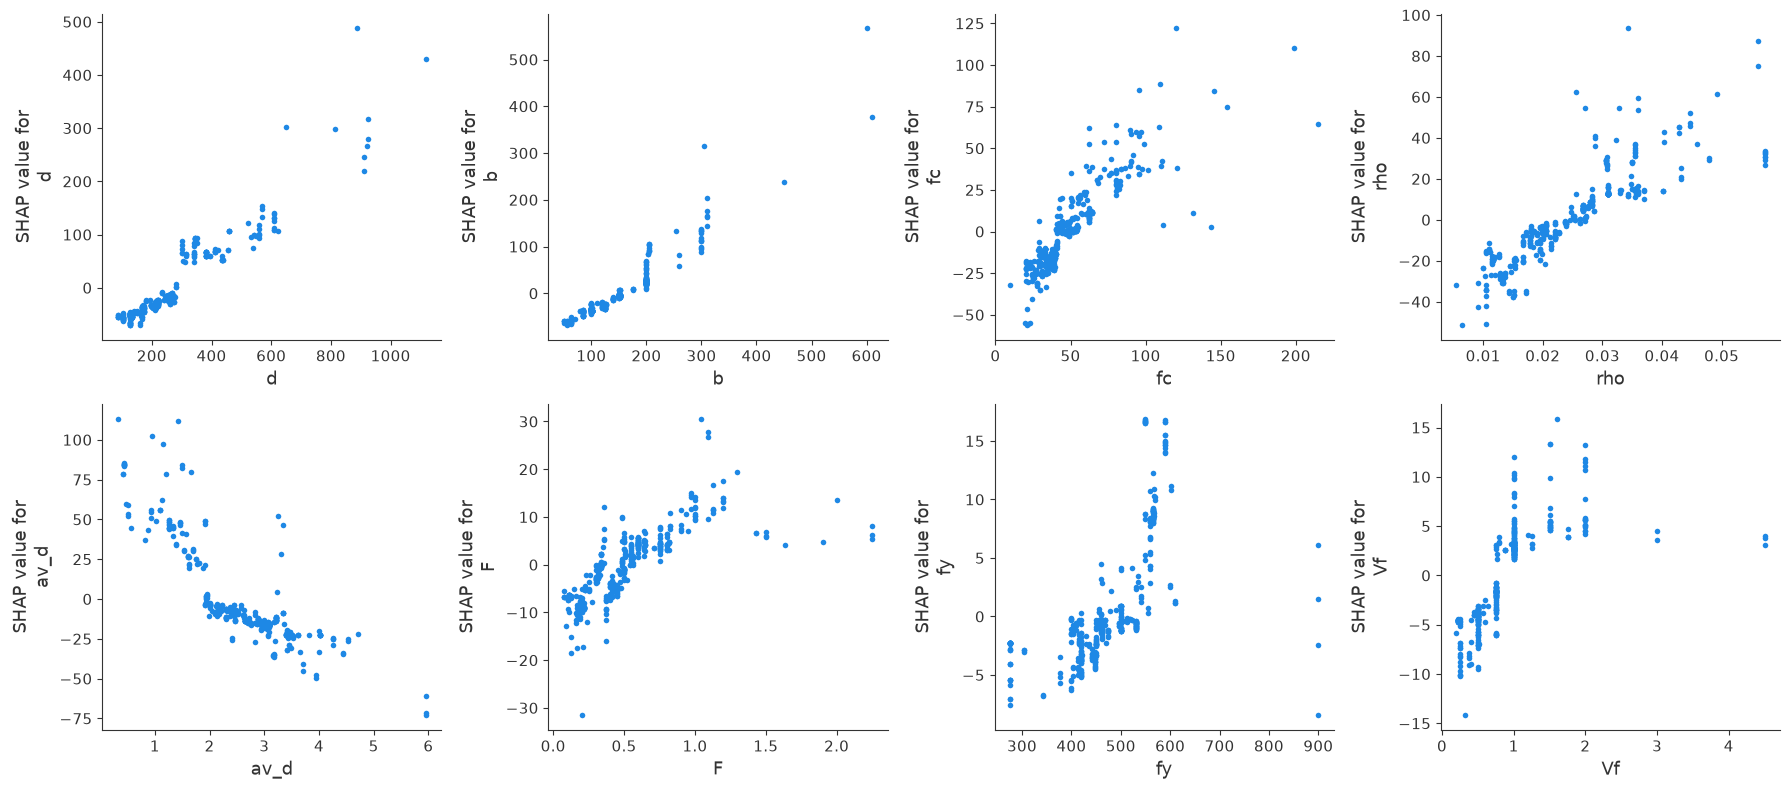

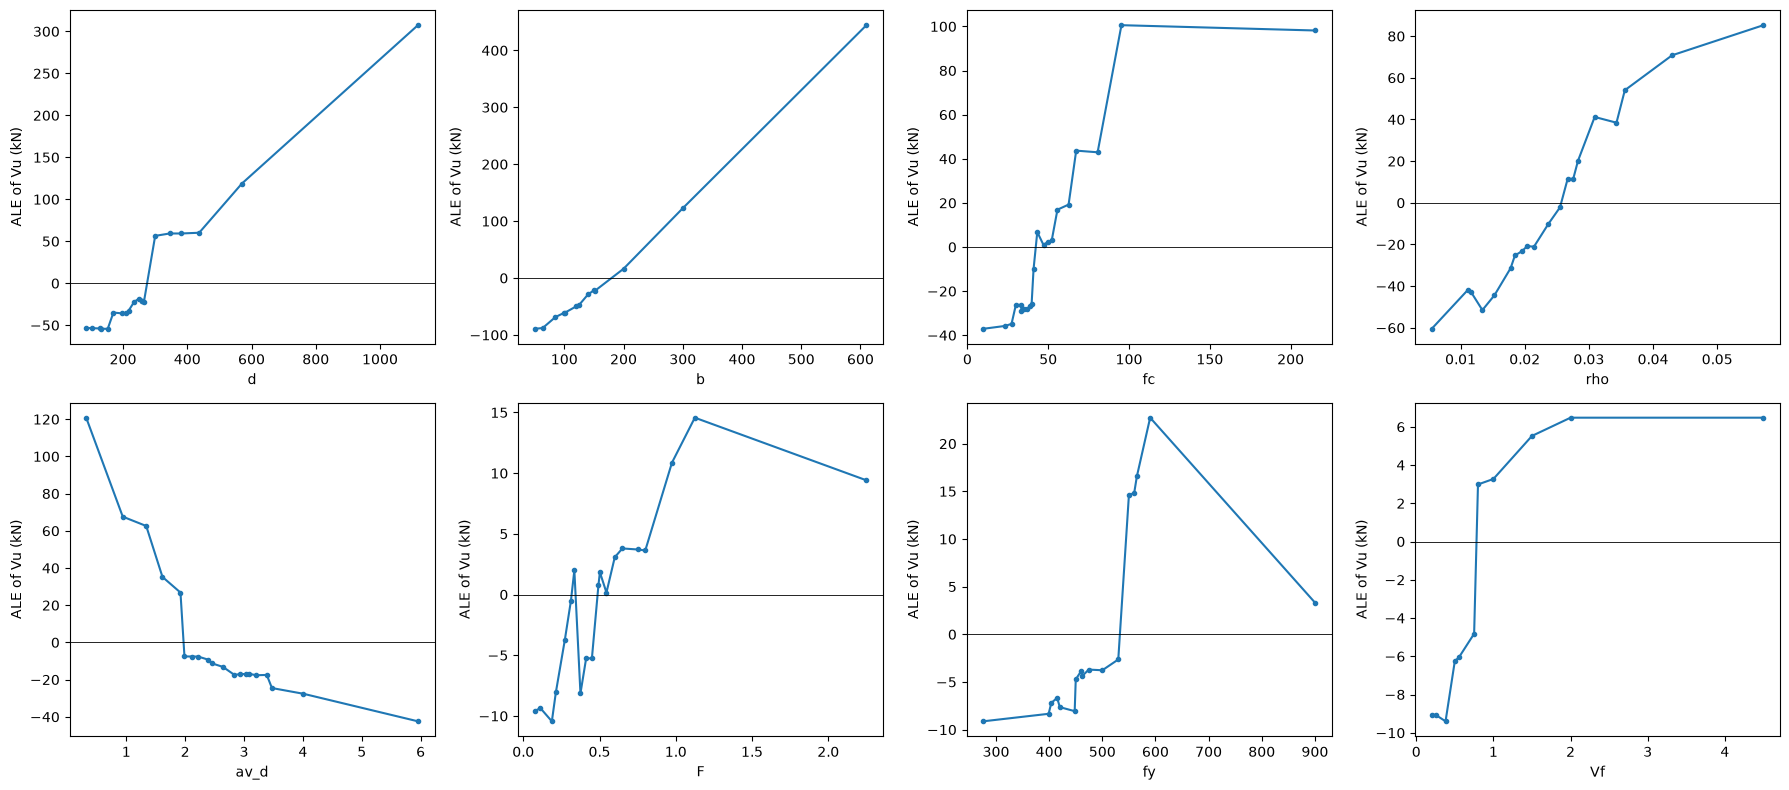

In [25]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, f in zip(axes.ravel(), FEATURES):
    shap.dependence_plot(f, sv.values, X_train, interaction_index=None, ax=ax, show=False)
plt.tight_layout(); plt.savefig("results/fig_shap_dependence.png", dpi=300); plt.show()

def ale_1d(model, data, feat, n_bins=20):
    x = data[feat].values
    q_ = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1)))
    idx = np.clip(np.searchsorted(q_, x, side="right") - 1, 0, len(q_) - 2)
    lo, hi = data.copy(), data.copy()
    lo[feat], hi[feat] = q_[idx], q_[idx + 1]
    d_ = model.predict(hi) - model.predict(lo)
    eff = np.array([d_[idx == k].mean() if (idx == k).any() else 0.0 for k in range(len(q_) - 1)])
    ale = np.concatenate([[0.0], np.cumsum(eff)])
    counts = np.bincount(idx, minlength=len(q_) - 1)
    ale -= np.sum((ale[:-1] + ale[1:]) / 2 * counts) / len(x)
    return q_, ale

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, f in zip(axes.ravel(), FEATURES):
    q_, a_ = ale_1d(best_xgb, X_train, f)
    ax.plot(q_, a_, "-o", ms=3); ax.axhline(0, color="k", lw=.6)
    ax.set_xlabel(f); ax.set_ylabel("ALE of Vu (kN)")
plt.tight_layout(); plt.savefig("results/fig_ale.png", dpi=300); plt.show()

### 12.4 Size effect: model the nominal shear stress instead of Vu
Vu grows with the cross-section (b·d), so depth and width will dominate any model of Vu. Modelling v = Vu / (b·d) in MPa removes that scale effect.

In [26]:
v = y * 1000.0 / (df["b"] * df["d"])                     
v_train, v_test = v.loc[X_train.index], v.loc[X_test.index]
m_v = xgb.XGBRegressor(random_state=SEED_MODEL, **best_params).fit(X_train, v_train)   # same hyperparameters, not re-tuned
pred_v = m_v.predict(X_test)
pred_Vu = pred_v * X_test["b"].values * X_test["d"].values / 1000.0
print("Stress model: test R2(v) = %.3f | converted back to Vu: R2 = %.3f, RMSE = %.2f kN"
      % (r2_score(v_test, pred_v), r2_score(y_test, pred_Vu), np.sqrt(mean_squared_error(y_test, pred_Vu))))

share_Vu = pd.Series(np.abs(sv.values).mean(0), index=FEATURES); share_Vu /= share_Vu.sum()
sv_v = np.abs(shap.TreeExplainer(m_v).shap_values(X_train)).mean(0)
share_v = pd.Series(sv_v, index=FEATURES); share_v /= share_v.sum()
target_cmp = pd.DataFrame({"share of mean |SHAP|, Vu target": share_Vu, "share, stress target v": share_v}).round(3)
target_cmp = target_cmp.sort_values("share, stress target v", ascending=False)
target_cmp.to_csv("results/shap_vu_vs_stress_target.csv")
target_cmp

Stress model: test R2(v) = 0.938 | converted back to Vu: R2 = 0.966, RMSE = 29.01 kN


,"share of mean |SHAP|, Vu target","share, stress target v"
av_d,0.138,0.393
rho,0.103,0.205
fc,0.116,0.162
F,0.035,0.114
Vf,0.026,0.051
d,0.326,0.036
fy,0.023,0.024
b,0.231,0.014


### 12.5 Reproducibility information (put this in the paper's Code and Data Availability section)

In [27]:
import sys, platform, sklearn, lime, statsmodels, matplotlib
run_info = {"python": sys.version.split()[0], "platform": platform.platform(), "numpy": np.__version__,
            "pandas": pd.__version__, "scikit-learn": sklearn.__version__, "xgboost": xgb.__version__,
            "shap": shap.__version__, "statsmodels": statsmodels.__version__, "matplotlib": matplotlib.__version__,
            "split random_state": SEED_SPLIT, "model random_state": SEED_MODEL, "bootstrap resamples": N_BOOT,
            "records": len(df), "best_params": str(best_params)}
pd.Series(run_info).to_csv("results/run_info.csv")
pd.Series(run_info)

python                                                            3.14.6
platform                                       Windows-11-10.0.22631-SP0
numpy                                                              2.4.6
pandas                                                             3.0.3
scikit-learn                                                       1.9.0
xgboost                                                            3.4.1
shap                                                              0.53.0
statsmodels                                                       0.15.0
matplotlib                                                        3.11.0
split random_state                                                    64
model random_state                                                    20
bootstrap resamples                                                   20
records                                                              488
best_params            {'colsample_bytree': 0.7, 'l